Primeras observaciones:
   Year  Average  Unnamed: 2
0  1870    53.60         NaN
1  1871    51.13         NaN
2  1872    50.98         NaN
3  1873    50.98         NaN
4  1874    51.34         NaN

Dimensiones de la base: (151, 3)

Periodo:
1870 - 2020

Número total de observaciones: 151


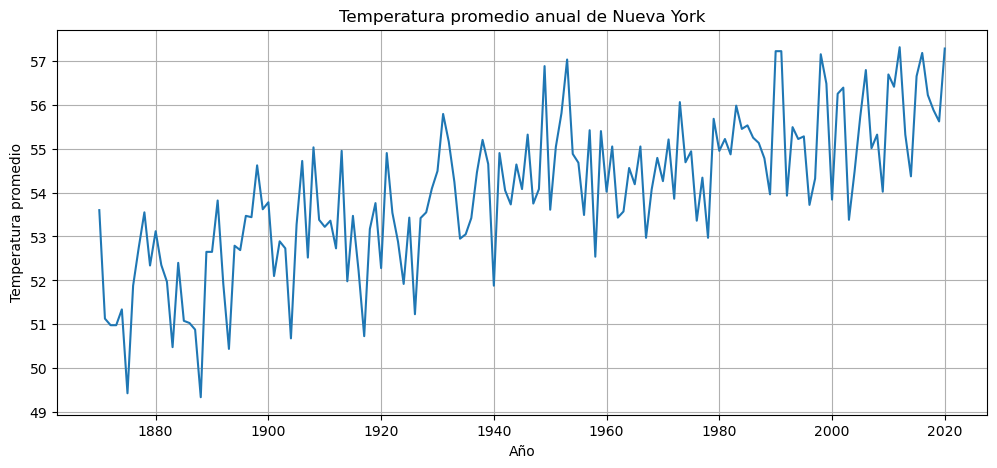


DIVISIÓN DE LOS DATOS
Total de observaciones: 151
Entrenamiento: 135
Prueba: 16
Años entrenamiento: 1870 - 2004
Años prueba: 2005 - 2020


In [3]:
# Temperaturas promedio de Nueva York 1870-2020

# Librerías
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings

from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_absolute_error, mean_squared_error

warnings.filterwarnings("ignore")

# Cargar datos

df = pd.read_csv("TempNY.csv")

# Mostrar información inicial
print("Primeras observaciones:")
print(df.head())

print("\nDimensiones de la base:", df.shape)

# Eliminar columnas que no contienen información
df = df[["Year", "Average"]].dropna()

# Ordenar por año
df = df.sort_values("Year")

# Convertir la temperatura a numérico
df["Average"] = pd.to_numeric(df["Average"], errors="coerce")

# Eliminar valores faltantes
df = df.dropna()

# Crear serie temporal
serie = df["Average"].astype(float)

print("\nPeriodo:")
print(df["Year"].min(), "-", df["Year"].max())

print("\nNúmero total de observaciones:", len(serie))



# Gráfica de la serie orginal


plt.figure(figsize=(12,5))

plt.plot(df["Year"], serie)

plt.title("Temperatura promedio anual de Nueva York")
plt.xlabel("Año")
plt.ylabel("Temperatura promedio")

plt.grid(True)
plt.show()


# Entrenamiento 90% Y Prueba 10%

n = len(serie)

n_train = int(n * 0.90)

train = serie.iloc[:n_train]
test = serie.iloc[n_train:]

years_train = df["Year"].iloc[:n_train]
years_test = df["Year"].iloc[n_train:]

print("\n==============================")
print("DIVISIÓN DE LOS DATOS")
print("==============================")

print("Total de observaciones:", n)
print("Entrenamiento:", len(train))
print("Prueba:", len(test))

print("Años entrenamiento:",
      years_train.min(), "-", years_train.max())

print("Años prueba:",
      years_test.min(), "-", years_test.max())


--------------------------------
PRUEBA ADF - SERIE ORIGINAL
--------------------------------
Estadístico ADF: -1.7177
p-value: 0.422012

Valores críticos:
1% : -3.4829
5% : -2.8846
10% : -2.5791

Conclusión: LA SERIE NO ES ESTACIONARIA.

DIFERENCIACIÓN
Número de diferencias necesarias: 1
p-value final: 1.5713108896119088e-13


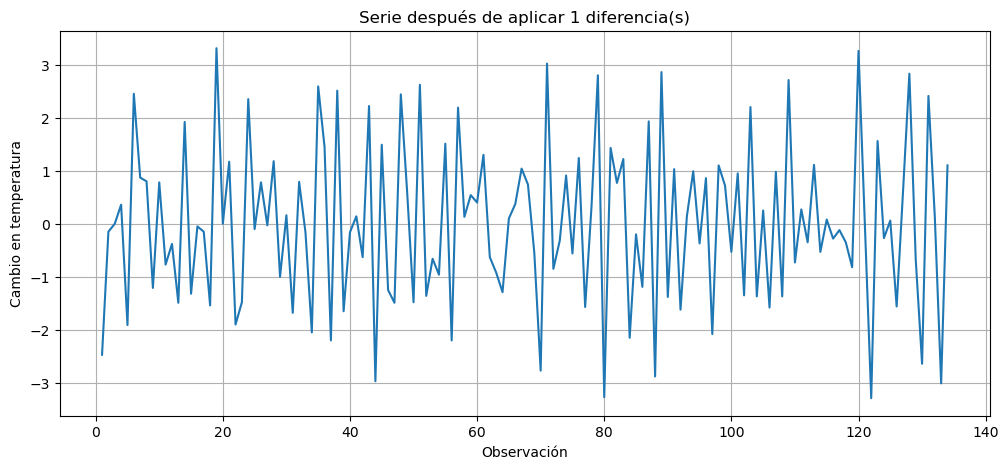


--------------------------------
PRUEBA ADF - SERIE DIFERENCIADA
--------------------------------
Estadístico ADF: -8.4606
p-value: 0.0

Valores críticos:
1% : -3.4829
5% : -2.8846
10% : -2.5791

Conclusión: LA SERIE ES ESTACIONARIA.

COMPARACIÓN DE MODELOS ARIMA

Modelos ordenados por AIC:
   Modelo  p  d  q        AIC        BIC
(3, 1, 3)  3  1  3 432.636599 452.921478
(0, 1, 1)  0  1  1 433.656509 439.452189
(4, 1, 4)  4  1  4 433.709141 459.789699
(4, 1, 3)  4  1  3 434.415507 457.598225
(2, 1, 3)  2  1  3 434.696016 452.083055
(1, 1, 1)  1  1  1 435.230115 443.923635
(2, 1, 2)  2  1  2 436.813381 451.302580
(2, 1, 1)  2  1  1 436.824147 448.415506
(3, 1, 2)  3  1  2 438.801199 456.188237
(3, 1, 1)  3  1  1 438.818350 453.307549
(1, 1, 0)  1  1  0 462.295330 468.091010
(0, 1, 0)  0  1  0 496.475203 499.373043

MODELO ÓPTIMO
ARIMA( 3 , 1 , 3 )
AIC: 432.6366
BIC: 452.9215

Resumen del modelo:
                               SARIMAX Results                                
Dep. Variabl

In [13]:
# Prueba de DICKEY-FULLER

def prueba_adf(datos, nombre):

    resultado = adfuller(datos, autolag="AIC")

    estadistico = resultado[0]
    p_valor = resultado[1]

    print("\n--------------------------------")
    print(nombre)
    print("--------------------------------")

    print("Estadístico ADF:", round(estadistico, 4))
    print("p-value:", round(p_valor, 6))

    print("\nValores críticos:")

    for clave, valor in resultado[4].items():
        print(clave, ":", round(valor, 4))

    if p_valor < 0.05:
        print("\nConclusión: LA SERIE ES ESTACIONARIA.")
    else:
        print("\nConclusión: LA SERIE NO ES ESTACIONARIA.")

    return p_valor


# Prueba sobre los datos originales
p_original = prueba_adf(
    train,
    "PRUEBA ADF - SERIE ORIGINAL"
)


# Diferenciación

d = 0
serie_estacionaria = train.copy()

while True:

    resultado = adfuller(
        serie_estacionaria,
        autolag="AIC"
    )

    p_valor = resultado[1]

    if p_valor < 0.05:
        break

    d += 1

    serie_estacionaria = train.diff(d).dropna()

print("\n==============================")
print("DIFERENCIACIÓN")
print("==============================")

print("Número de diferencias necesarias:", d)

print("p-value final:", p_valor)


# ============================================================
# 7. GRÁFICA DE LA SERIE DIFERENCIADA
# ============================================================

plt.figure(figsize=(12,5))

plt.plot(
    serie_estacionaria.index,
    serie_estacionaria
)

plt.title(
    "Serie después de aplicar "
    + str(d)
    + " diferencia(s)"
)

plt.xlabel("Observación")
plt.ylabel("Cambio en temperatura")

plt.grid(True)
plt.show()


# ============================================================
# 8. PRUEBA ADF DESPUÉS DE DIFERENCIAR
# ============================================================

prueba_adf(
    serie_estacionaria,
    "PRUEBA ADF - SERIE DIFERENCIADA"
)


# ============================================================
# 9. COMPARACIÓN DE MODELOS ARIMA
# ============================================================

# Probamos diferentes combinaciones de p, d y q.
# Como la prueba ADF indicó d = 1,
# utilizamos d = 1.

modelos = [
    (0, 1, 0),
    (0, 1, 1),
    (1, 1, 0),
    (1, 1, 1),
    (2, 1, 1),
    (2, 1, 2),
    (2, 1, 3),
    (3, 1, 1),
    (3, 1, 2),
    (3, 1, 3),
    (4, 1, 3),
    (4, 1, 4)
]

resultados = []

print("\n==============================")
print("COMPARACIÓN DE MODELOS ARIMA")
print("==============================")

for orden in modelos:

    try:

        modelo = ARIMA(
            train,
            order=orden
        )

        ajuste = modelo.fit()

        resultados.append({
            "Modelo": str(orden),
            "p": orden[0],
            "d": orden[1],
            "q": orden[2],
            "AIC": ajuste.aic,
            "BIC": ajuste.bic
        })

    except Exception as error:

        print(
            "No fue posible ajustar:",
            orden
        )


# Convertir resultados a DataFrame
resultados = pd.DataFrame(resultados)

# Ordenar por AIC
resultados = resultados.sort_values("AIC")

print("\nModelos ordenados por AIC:")
print(resultados.to_string(index=False))


# ============================================================
# 10. SELECCIONAR EL MODELO ÓPTIMO
# ============================================================

mejor_modelo = resultados.iloc[0]

p_optimo = int(mejor_modelo["p"])
d_optimo = int(mejor_modelo["d"])
q_optimo = int(mejor_modelo["q"])

print("\n==============================")
print("MODELO ÓPTIMO")
print("==============================")

print(
    "ARIMA(",
    p_optimo,
    ",",
    d_optimo,
    ",",
    q_optimo,
    ")"
)

print("AIC:", round(mejor_modelo["AIC"], 4))
print("BIC:", round(mejor_modelo["BIC"], 4))


# ============================================================
# 11. AJUSTAR EL MODELO ÓPTIMO
# ============================================================

modelo_optimo = ARIMA(
    train,
    order=(
        p_optimo,
        d_optimo,
        q_optimo
    )
)

ajuste_optimo = modelo_optimo.fit()

print("\nResumen del modelo:")
print(ajuste_optimo.summary())


# ============================================================
# 12. PRONÓSTICOS PARA LOS DATOS DE PRUEBA
# ============================================================

pronostico = ajuste_optimo.get_forecast(
    steps=len(test)
)

# Predicción puntual
predicciones = pronostico.predicted_mean

# Intervalos de confianza del 95 %
intervalos = pronostico.conf_int(alpha=0.05)

# Límites inferior y superior
limite_inferior = intervalos.iloc[:, 0]
limite_superior = intervalos.iloc[:, 1]


# ============================================================
# 13. TABLA DE PREDICCIONES
# ============================================================

tabla_predicciones = pd.DataFrame({

    "Año": years_test.values,

    "Real": test.values,

    "Predicción": predicciones.values,

    "Límite inferior 95%":
        limite_inferior.values,

    "Límite superior 95%":
        limite_superior.values

})

print("\n==============================")
print("PREDICCIONES")
print("==============================")

print(
    tabla_predicciones.round(2).to_string(index=False)
)




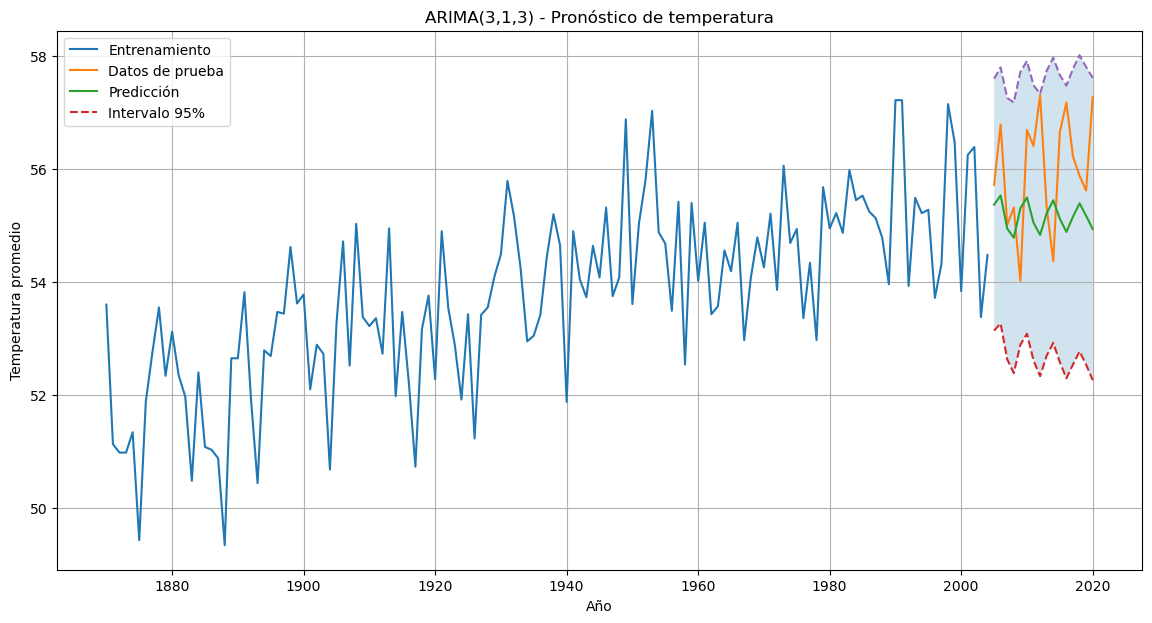

In [11]:
# GRÁFICA FINAL

plt.figure(figsize=(14,7))

# Datos de entrenamiento
plt.plot(
    years_train,
    train,
    label="Entrenamiento"
)

# Datos reales de prueba
plt.plot(
    years_test,
    test,
    label="Datos de prueba"
)

# Predicciones
plt.plot(
    years_test,
    predicciones,
    label="Predicción"
)

# Intervalo inferior
plt.plot(
    years_test,
    limite_inferior,
    linestyle="--",
    label="Intervalo 95%"
)

# Intervalo superior
plt.plot(
    years_test,
    limite_superior,
    linestyle="--"
)

# Sombrear intervalo
plt.fill_between(
    years_test,
    limite_inferior,
    limite_superior,
    alpha=0.2
)

plt.title(
    "ARIMA("
    + str(p_optimo)
    + ","
    + str(d_optimo)
    + ","
    + str(q_optimo)
    + ") - Pronóstico de temperatura"
)

plt.xlabel("Año")
plt.ylabel("Temperatura promedio")

plt.legend()
plt.grid(True)

plt.show()

In [15]:
# INDICADORES DE ERROR


mae = mean_absolute_error(
    test,
    predicciones
)

mse = mean_squared_error(
    test,
    predicciones
)

rmse = np.sqrt(mse)

mape = np.mean(
    np.abs(
        (test - predicciones) / test
    )
) * 100


# Cobertura del intervalo de confianza

dentro_intervalo = (
    (test >= limite_inferior) &
    (test <= limite_superior)
)

cobertura = dentro_intervalo.mean() * 100


# RESULTADOS


print("\n==============================")
print("INDICADORES DE ERROR")
print("==============================")

print("MAE  =", round(mae, 4))
print("MSE  =", round(mse, 4))
print("RMSE =", round(rmse, 4))
print("MAPE =", round(mape, 2), "%")

print(
    "Cobertura del intervalo 95% =",
    round(cobertura, 2),
    "%"
)


# CONCLUSIÓN 


print("\n==============================")
print("CONCLUSIÓN")
print("==============================")

print(
    "La serie original presentó un p-value de",
    round(p_original, 6),
    "en la prueba Dickey-Fuller."
)

print(
    "Por lo tanto, no fue estacionaria al nivel original."
)

print(
    "Se aplicó",
    d,
    "diferencia(s) para alcanzar la estacionariedad."
)

print(
    "El modelo seleccionado mediante AIC fue ARIMA(",
    p_optimo,
    ",",
    d_optimo,
    ",",
    q_optimo,
    ")."
)

print(
    "El MAE fue:",
    round(mae, 4)
)

print(
    "El RMSE fue:",
    round(rmse, 4)
)

print(
    "El MAPE fue:",
    round(mape, 2),
    "%"
)

print(
    "El",
    round(cobertura, 2),
    "% de los valores reales quedó dentro del intervalo de confianza del 95%."
)


INDICADORES DE ERROR
MAE  = 1.1164
MSE  = 1.8042
RMSE = 1.3432
MAPE = 1.98 %
Cobertura del intervalo 95% = 100.0 %

CONCLUSIÓN
La serie original presentó un p-value de 0.422012 en la prueba Dickey-Fuller.
Por lo tanto, no fue estacionaria al nivel original.
Se aplicó 1 diferencia(s) para alcanzar la estacionariedad.
El modelo seleccionado mediante AIC fue ARIMA( 3 , 1 , 3 ).
El MAE fue: 1.1164
El RMSE fue: 1.3432
El MAPE fue: 1.98 %
El 100.0 % de los valores reales quedó dentro del intervalo de confianza del 95%.
